In [13]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
import seaborn as sns


In [14]:
data=load_breast_cancer()

In [15]:
df=pd.DataFrame(data.data,columns=data.feature_names)


In [16]:
df['target']=data.target

In [18]:
print("First 5 rows:")
print(df.head())

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \


In [19]:
print("\nShape of the dataset")
print(df.shape)


Shape of the dataset
(569, 31)


In [20]:
print("\nDataset Information")
df.info()


Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error

In [21]:
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [22]:
df=df.drop_duplicates()

In [23]:
print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())
      


Duplicate rows after cleaning:
0


In [11]:
print("\nStatistical summary: ")
print(df.describe())


Statistical summary: 
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000           

In [24]:
print("\nFinal shape of dataset: ")
print(df.shape)


Final shape of dataset: 
(569, 31)


1. CLASS DISTRIBUTION

In [25]:
class_counts=df['target'].value_counts()
class_percentages=df['target'].value_counts(normalize=True)*100
print("Class Counts: ")
print(class_counts)
print("\nClass Percentages: ")
print(class_percentages)
print("\nClass Names: ")
print(data.target_names)


Class Counts: 
target
1    357
0    212
Name: count, dtype: int64

Class Percentages: 
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64

Class Names: 
['malignant' 'benign']


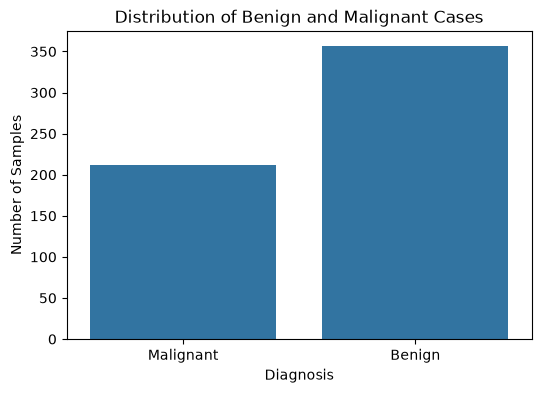

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(x='target',data=df)
plt.title('Distribution of Benign and Malignant Cases')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Samples')
plt.xticks([0,1],['Malignant','Benign'])
plt.show()

Observation: The dataset contains 357 benign samples (62.74%) and 212 malignant samples (37.26%). Therefore, benign cases are more frequent, but both classes have a substantial number of samples.
ML implication: The classes are not perfectly balanced. Therefore, class distribution should be considered when evaluating the classification model, and accuracy alone may not be sufficient. Metrics such as precision, recall, F1-score and confusion matrix should also be considered.

2. FEATURE DISTRIBUTIONS
   

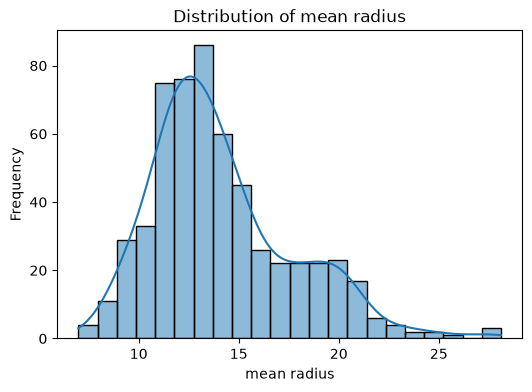

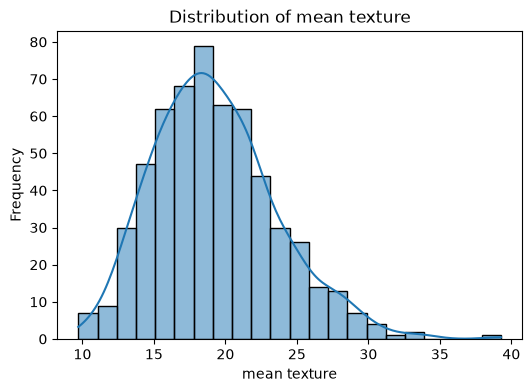

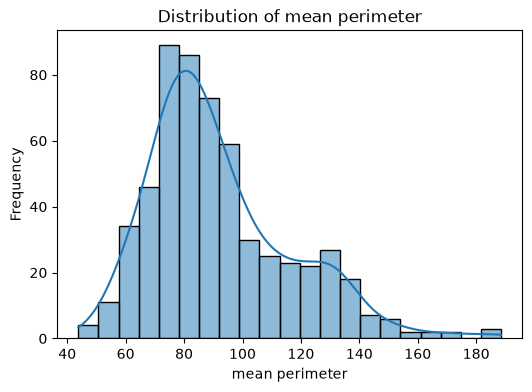

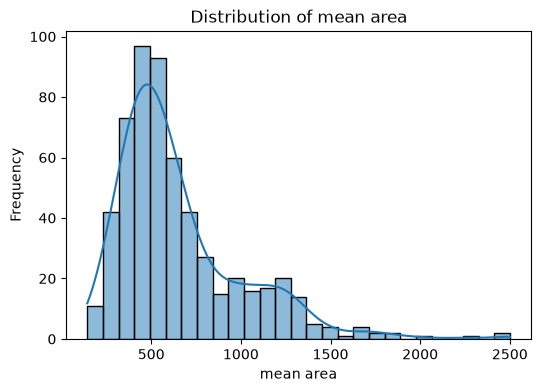

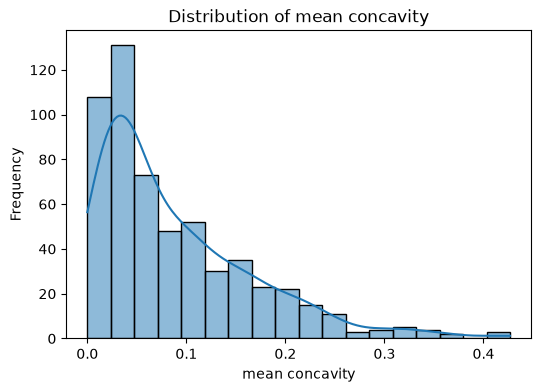

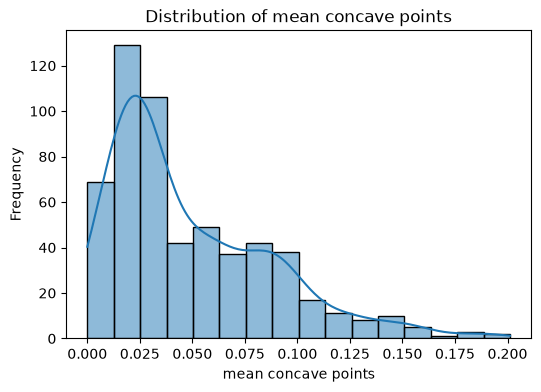

In [27]:
selected_features=[
    'mean radius',
     'mean texture',
     'mean perimeter',
     'mean area',
     'mean concavity',
     'mean concave points'
]
for feature in selected_features:
    plt.figure(figsize=(6,4))
    sns.histplot(df[feature],kde=True)
    plt.title('Distribution of '+feature)
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()
    
    


    
    

Observation: The selected numerical features show different ranges and distributions. Some features, such as mean radius, mean perimeter and mean area, show a wider spread of values, while others have more concentrated distributions. The distributions also indicate that the features are measured on very different numerical scales.

ML implication: Since the features have different scales and ranges, feature scaling may be important before applying certain machine-learning algorithms, particularly distance-based algorithms such as KNN.

3. FEATURE VS DIAGNOSIS

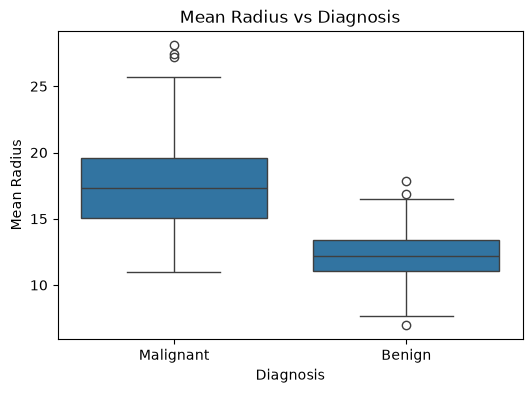

In [28]:
#Mean Radius
plt.figure(figsize=(6,4))
sns.boxplot(x='target',y='mean radius',data=df)
plt.title('Mean Radius vs Diagnosis') 
plt.xlabel('Diagnosis')
plt.ylabel('Mean Radius')
plt.xticks([0,1],['Malignant','Benign'])
plt.show()


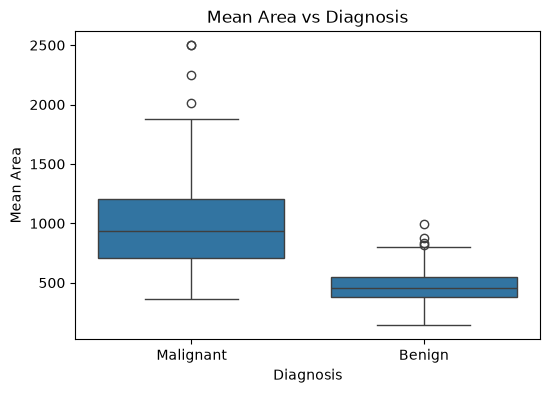

In [29]:
#Mean Area
plt.figure(figsize=(6,4))
sns.boxplot(x='target',y='mean area',data=df)
plt.title('Mean Area vs Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Mean Area')
plt.xticks([0,1],['Malignant','Benign'])
plt.show()

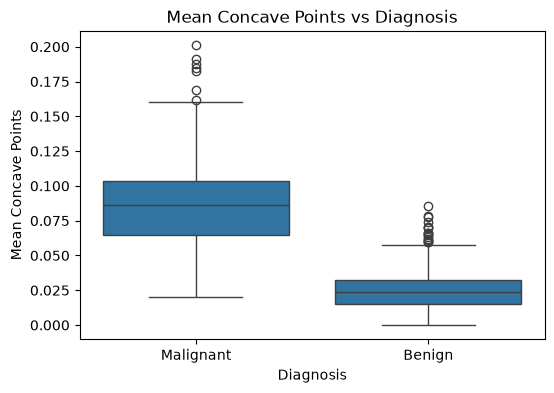

In [31]:
#Mean Concave Points
plt.figure(figsize=(6,4))
sns.boxplot(x='target',y='mean concave points',data=df)
plt.title('Mean Concave Points vs Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Mean Concave Points')
plt.xticks([0,1],['Malignant','Benign'])
plt.show()

Observation: The distributions of mean radius, mean area and mean concave points differ noticeably between malignant and benign samples. Malignant samples generally show higher values for these features.

For example, the average mean radius is approximately:

Malignant → 17.46
Benign → 12.15

And mean area:

Malignant → 978.38
Benign → 462.79

ML implication: The noticeable differences between the two classes suggest that these features may contain useful information for distinguishing malignant from benign samples. Therefore, such features may contribute to classification performance.

4. CORRELATION ANALYSIS

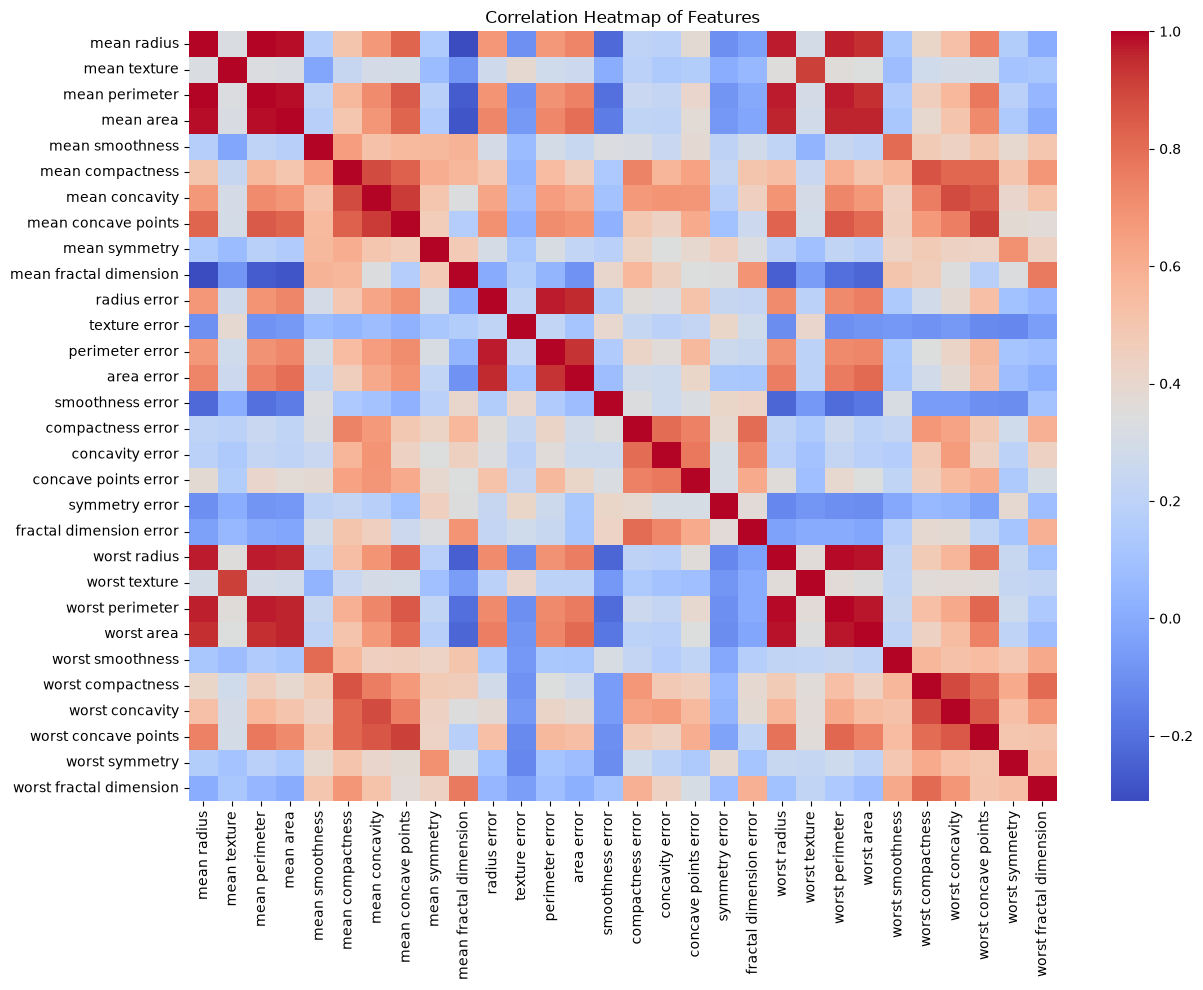

In [33]:
plt.figure(figsize=(14,10))
correlation_matrix=df.drop('target',axis=1).corr()
sns.heatmap(
    correlation_matrix,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap of Features')
plt.show()

Observation: Several features show very strong positive correlations. For example, mean radius, mean perimeter and mean area are highly correlated with one another.
Mean radius ↔ Mean perimeter

Correlation ≈ 0.998

Mean radius ↔ Mean area

Correlation ≈ 0.987

Mean perimeter ↔ Mean area

Correlation ≈ 0.987

These are extremely high correlations.

ML implication: Highly correlated features may contain overlapping or redundant information. This can introduce multicollinearity and may make some models more complex without adding much new information. Feature selection or dimensionality-reduction techniques could therefore be considered during later stages.

5. OUTLIER ANALYSIS

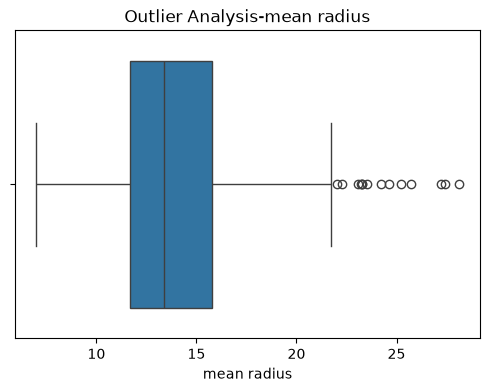

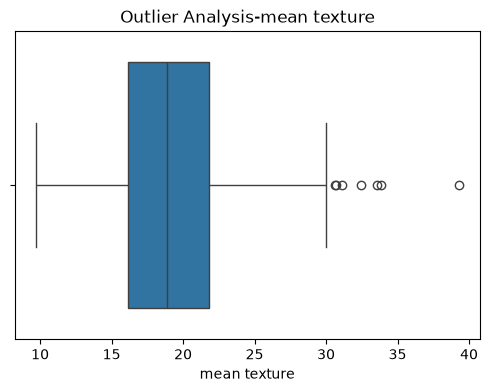

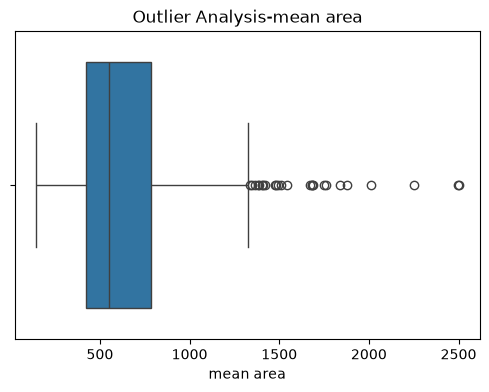

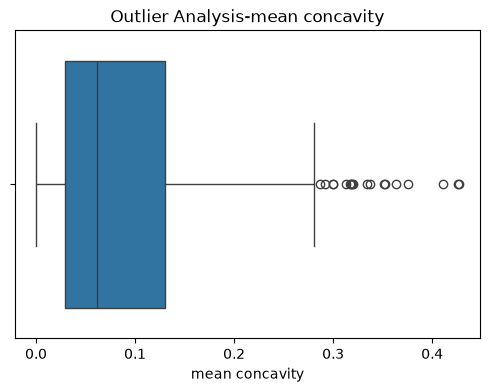

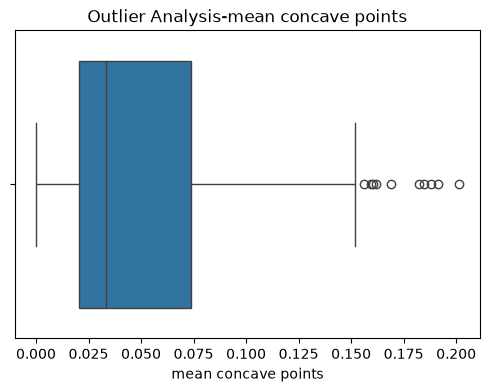

In [34]:
outlier_features=[
    'mean radius',
     'mean texture',
     'mean area',
     'mean concavity',
     'mean concave points'
     
    
]
for feature in outlier_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[feature])
    plt.title('Outlier Analysis-'+feature)
    plt.xlabel(feature)
    plt.show()

Observation: Boxplots indicate the presence of potential outliers in some numerical features. These observations lie outside the typical range defined by the boxplot whiskers.

ML implication: Potential outliers were identified but were not automatically removed because they may represent genuine biological variation rather than errors. Removing them without justification could result in loss of useful information. Their effect can instead be considered during preprocessing and model evaluation.

6.FEATURE RELATIONSHIP ANALYSIS

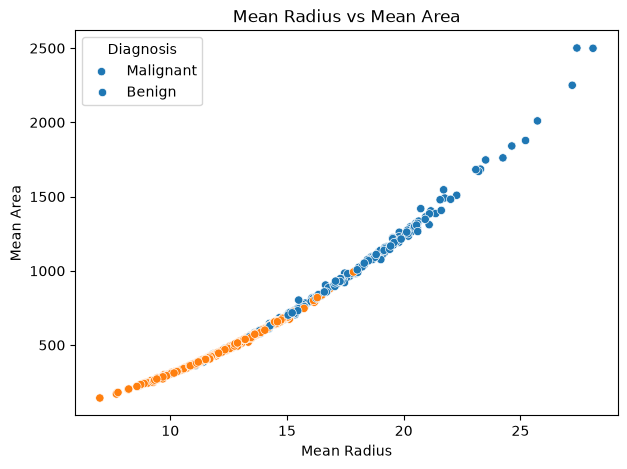

In [35]:
#Radius vs Area
plt.figure(figsize=(7,5))
sns.scatterplot(
    x='mean radius',
    y='mean area',
    hue='target',
    data=df
)
plt.title('Mean Radius vs Mean Area')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Area')
plt.legend(title='Diagnosis',labels=['Malignant','Benign'])
plt.show()

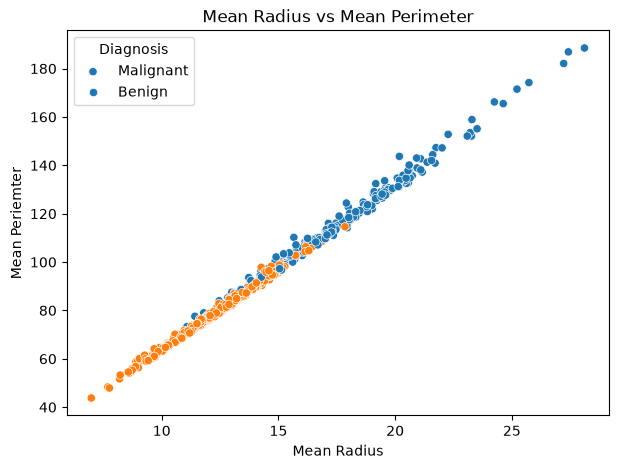

In [36]:
#Radius vs Perimeter
plt.figure(figsize=(7,5))
sns.scatterplot(
    x='mean radius',
    y='mean perimeter',
    hue='target',
    data=df
)
plt.title('Mean Radius vs Mean Perimeter')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Periemter')
plt.legend(title='Diagnosis',labels=['Malignant','Benign'])
plt.show()


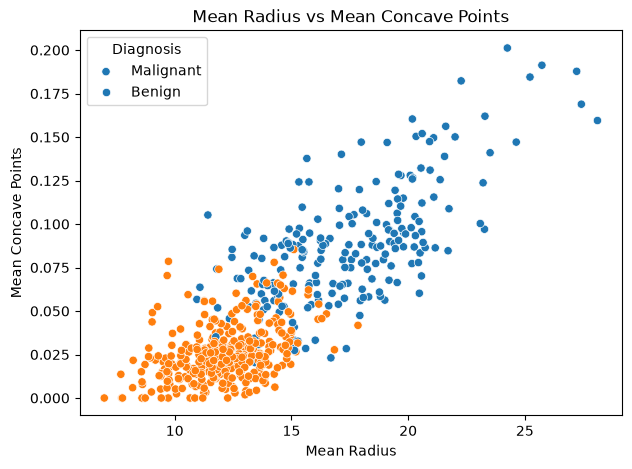

In [37]:
#Concave Points vs Radius
plt.figure(figsize=(7,5))
sns.scatterplot(
    x='mean radius',
    y='mean concave points',
    hue='target',
    data=df
)
plt.title('Mean Radius vs Mean Concave Points')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Concave Points')
plt.legend(title='Diagnosis',labels=['Malignant','Benign'])
plt.show()

Observation: Mean radius shows a strong positive relationship with mean area and mean perimeter. The malignant and benign samples also show some separation in the feature relationships, although there is still overlap between the classes.


ML implication: The relationships and partial separation between classes suggest that multiple features may provide useful information for classification. However, because the classes overlap, using multiple features together may be more effective than relying on a single feature.

7. PAIRPLOT


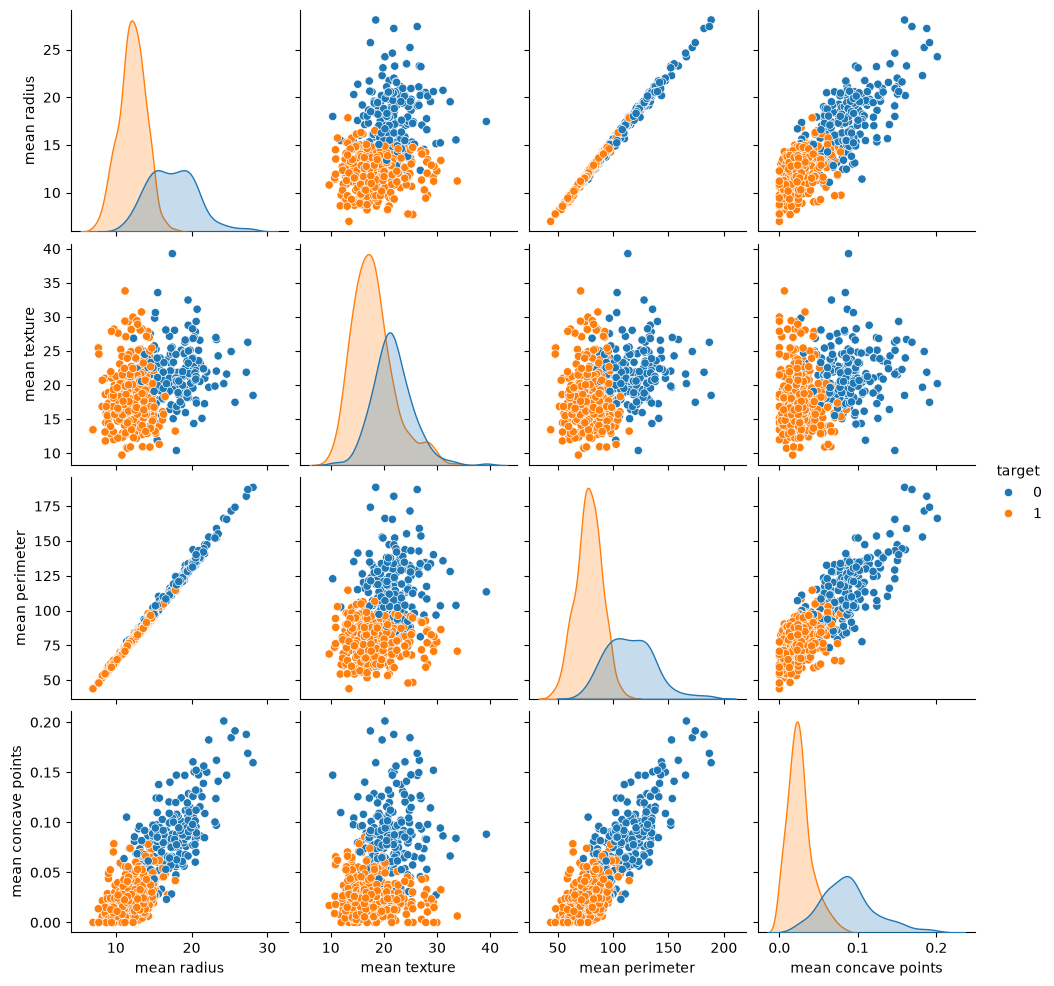

In [39]:
pairplot_features=[
    'mean radius',
     'mean texture',
     'mean perimeter',
     'mean concave points',
    'target'
     
     
    
    
]
sns.pairplot(
    df[pairplot_features],
    hue='target'
)
plt.show()

Observation: The pairplot shows relationships among the selected features and indicates that some combinations of features provide better separation between malignant and benign samples than individual features alone.



ML implication: The observations support using multiple features for classification rather than depending on a single feature.

## EDA Conclusion

- The dataset contains more benign cases than malignant cases.
- Important features such as mean radius, mean area, and mean concave points show differences between the two diagnosis classes.
- Several features are strongly correlated, indicating some redundancy.
- Potential outliers were observed, but they were not removed because they may represent genuine observations.
- Feature relationship analysis shows that multiple features may be useful for distinguishing benign and malignant cases.
- These findings support moving to the data preprocessing and machine-learning stage.